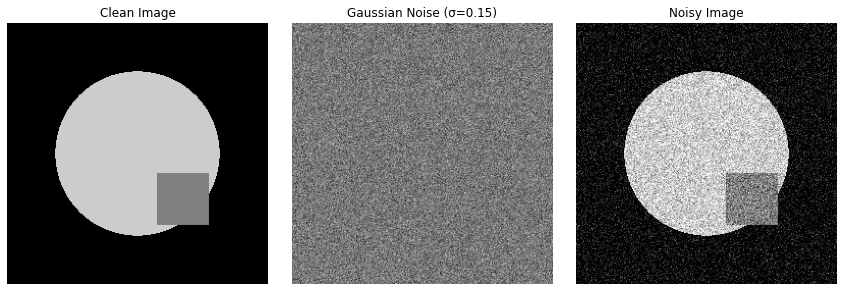

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a clean base grayscale image (256x256) in range [0, 1]
N = 256
x = np.linspace(-1, 1, N)
X, Y = np.meshgrid(x, x)

clean_img = np.zeros((N, N), dtype=np.float32)
clean_img[(X**2 + Y**2) < 0.4] = 0.8                                   # Circle
clean_img[(np.abs(X - 0.35) < 0.2) & (np.abs(Y - 0.35) < 0.2)] = 0.5   # Square

# 2. Generate Gaussian noise: N(mean, sigma^2) using NumPy only
rng = np.random.default_rng(seed=42)
mean = 0.0
sigma = 0.15  # Standard deviation controls noise intensity

gaussian_noise = rng.normal(loc=mean, scale=sigma, size=clean_img.shape)

# 3. Add noise and clip pixel values to valid [0, 1] range
noisy_img = np.clip(clean_img + gaussian_noise, 0.0, 1.0)

# 4. Visualize Clean Image, Noise, and Noisy Output
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(clean_img, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Clean Image")

axes[1].imshow(gaussian_noise, cmap="gray")
axes[1].set_title(f"Gaussian Noise (σ={sigma})")

axes[2].imshow(noisy_img, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Noisy Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()